<!-- CURRICULUM_HEADER_START -->
<div class="mh"><p class="mh-crumb"><a href="/series/forecasting/index.html">Forecasting with Machine Learning</a><span class="sep">·</span>Part 9 · Evaluating forecasts</p><p class="mh-facts"><span class="lvl lvl-intermediate">Intermediate</span></p><p class="mh-assumes">Python and pandas. Basic statistics. No prior forecasting.</p></div>
<!-- CURRICULUM_HEADER_END -->

::: {.callout-note appearance="simple" icon=false}
## TL;DR

A backtest that ranks two forecasting models is an experiment whose sample size is the number of seasons, not weeks. On a synthetic weekly harvest series, a model averaging the last two seasons has a mean absolute error $7\%$ below one copying last season, yet wins only $62\%$ of single seasons and $87\%$ of ten-season backtests. Compare models on the same origins and test the paired gap with one value per season: weekly tests raised false alarms in $13$ to $52\%$ of backtests where the models were equally good, a t-test over seasons in $6.5\%$. Confirming this $7\%$ gain would take about $73$ seasons. Score the weeks decisions use, refit only as often as it matters, tune inside each origin, and score a frozen final season once.

Before switching models, count the seasons behind the switch.
:::

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

# fallcolor is the site's colour module in tools/, not an installed package.
here = [Path.cwd(), *Path.cwd().parents]
sys.path.insert(0, str(next(p / "tools" for p in here if (p / "tools/fallcolor.py").exists())))
import fallcolor

fallcolor.palette.use("default")
plt.rcParams["figure.dpi"] = 110
C1, C2, C3, C4 = fallcolor.palette.discrete("default")
P, H = 52, 4                    # weeks per season; the decision horizon
FIRST, LAST = 5 * P, 15 * P     # backtest targets: seasons 6 to 15

[Backtesting properly](../backtesting/backtesting_properly.ipynb) set out the mechanics and advised reporting the season-to-season spread. This module uses that spread to decide whether one model beats another, then covers scoring, refitting, tuning and holding back.

The data are **synthetic**, from that module's generator with fixed seeds: weekly harvest in tonnes per week (t/week), one bell-shaped season a year whose height and timing vary, plus autocorrelated noise. Each history has 16 seasons: 1 to 5 warm up, 6 to 15 are the backtest (520 weekly targets), 16 is frozen. Forecasts are issued weekly for $h = 4$ weeks ahead and refitted every four weeks on targets observed by the origin. Both models are least-squares regressions:

$$\hat{y}_{t+h \mid t} = \beta_0 + \beta_1 y_t + \beta_2 r_k(t) + \beta_3 r_k(t+h), \qquad r_k(\tau) = \frac{1}{k} \sum_{j=1}^{k} y_{\tau - 52j}$$

where $y_t$ is the harvest in origin week $t$ (t/week), $r_k(\tau)$ the mean harvest in the same week of the previous $k$ seasons (t/week), $\beta_0$ an intercept (t/week) and $\beta_1$ to $\beta_3$ dimensionless weights. **Model A** uses last season ($k = 1$), **model B** the last two ($k = 2$).

In [2]:
def simulate(seed, seasons=16):
    """Synthetic weekly harvest (t/week), as in Backtesting properly."""
    rng = np.random.default_rng(seed)
    t = np.arange(seasons * P)
    size = rng.normal(100, 20, seasons)  # peak height, varies by season
    peak = rng.normal(26, 2.5, seasons)  # week of peak, varies by season
    shape = np.exp(-0.5 * ((t % P - peak[t // P]) / 5) ** 2)
    noise = np.zeros(len(t))
    for i in range(1, len(t)):  # AR(1) week-to-week noise
        noise[i] = 0.7 * noise[i - 1] + rng.normal(0, 4)
    return np.clip(5 + size[t // P] * shape + noise, 0, None)


def rows(y, h, k):  # one row per origin t: [1, y_t, r_k(t), r_k(t+h)], target y_{t+h}
    r = np.full(len(y), np.nan)
    for tau in range(k * P, len(y)):  # mean of the same week in the last k seasons
        r[tau] = y[tau - P * np.arange(1, k + 1)].mean()
    t = np.arange(k * P, len(y) - h)
    return t, np.column_stack([np.ones(len(t)), y[t], r[t], r[t + h]]), y[t + h]


def fit(X, z):
    return np.linalg.lstsq(X, z, rcond=None)[0]


def backtest(y, k, h=H, first=FIRST, last=LAST, every=4):
    """Rolling origin: absolute errors for targets in [first, last), refit every few weeks."""
    t, X, z = rows(y, h, k)
    test = np.flatnonzero((t + h >= first) & (t + h < last))
    pred = np.empty(len(test))
    for i in range(0, len(test), every):
        known = t + h <= t[test[i]]  # only targets observed by the origin
        pred[i:i + every] = X[test[i:i + every]] @ fit(X[known], z[known])
    return t[test] + h, np.abs(z[test] - pred)  # target week, |error|

## Seasons, not weeks, are the sample

On one history, the mean absolute error (MAE, t/week, as in [Which metric](../which-metric.qmd)) of each model by season:

In [3]:
y = simulate(seed=0)
week, err_a = backtest(y, k=1)
_, err_b = backtest(y, k=2)
season = week // P + 1
one = pd.DataFrame({"A, last season": err_a, "B, two-season mean": err_b}).groupby(season).mean()
one["A minus B"] = one.iloc[:, 0] - one.iloc[:, 1]
print(f"10 seasons: A {err_a.mean():.2f}, B {err_b.mean():.2f} t/week; B ahead in {(one.iloc[:, 2] > 0).sum()}")
one.round(2)

10 seasons: A 10.07, B 9.02 t/week; B ahead in 7


,"A, last season","B, two-season mean",A minus B
6,11.54,7.21,4.33
7,19.27,15.30,3.97
8,11.82,8.38,3.43
9,7.52,10.75,-3.23
10,7.75,6.63,1.12
11,10.44,11.45,-1.01
12,6.86,7.62,-0.76
13,7.75,7.37,0.38
14,10.34,9.04,1.30
15,7.38,6.45,0.93


B scores $9.02$ against A's $10.07$ and is ahead in 7 of 10 seasons, but the per-season gap runs from $+4.33$ to $-3.23$ t/week. Whether B is better or this history was kind to it, one history cannot say. Two hundred can:

In [4]:
histories = [simulate(seed) for seed in range(200)]
E_a, E_b = (np.array([backtest(h_, k)[1] for h_ in histories]) for k in (1, 2))
D = E_a - E_b  # the loss gap, one row per history, one column per target week
by_season = D.reshape(200, 10, P).mean(axis=2)  # one gap per season, t/week
mu, sd = D.mean(), by_season.std(ddof=1)
print(f"MAE A {E_a.mean():.2f}, B {E_b.mean():.2f}; mean gap {mu:.2f} t/week; season-to-season sd {sd:.2f}")
for n in (1, 2, 5, 10):
    print(f"B ahead over the first {n:>2} seasons in {(by_season[:, :n].mean(1) > 0).mean():.0%} of histories")
print(f"seasons for an 80% chance of p < 0.05: {((1.96 + 0.84) * sd / mu) ** 2:.0f}")

MAE A 11.83, B 10.97; mean gap 0.86 t/week; season-to-season sd 2.62
B ahead over the first  1 seasons in 62% of histories
B ahead over the first  2 seasons in 64% of histories
B ahead over the first  5 seasons in 72% of histories
B ahead over the first 10 seasons in 87% of histories
seasons for an 80% chance of p < 0.05: 73


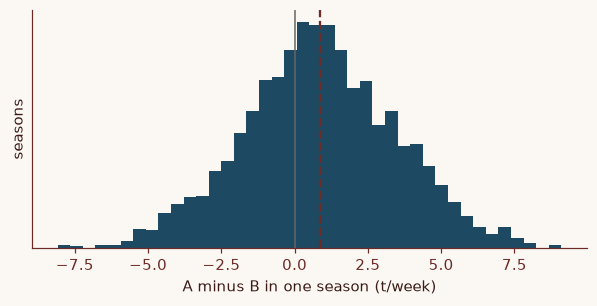

In [5]:
fig, ax = plt.subplots(figsize=(6.5, 2.8))
ax.hist(by_season.ravel(), bins=40, color=C1)
ax.axvline(0, color="0.4", lw=1)
ax.axvline(mu, color=C3, lw=1.5, ls="--")
ax.set(xlabel="A minus B in one season (t/week)", ylabel="seasons", yticks=[])
plt.show()

**Figure 1 | The gap varies more between seasons than its average.** Per-season MAE of A minus B, 10 seasons in each of 200 synthetic histories; positive favours B. Grey, no difference; dashed, the mean gap of $0.86$ t/week.

On average A's MAE is $11.83$ and B's $10.97$, a gap of $0.86$ t/week, $0.86 / 11.83 = 7\%$ of A's error. The gap's season-to-season standard deviation is $2.62$ t/week, three times the gap. B is ahead in $62\%$ of single seasons and $87\%$ of ten-season backtests, but "ahead" means only that its average was lower; a test detects the gap far less often.

With seasons as the observations, the sample-size rule of [Power, and how many samples](../power-and-how-many-samples.qmd) for a one-sample test is

$$n \approx \left( \frac{(z_{0.975} + z_{0.80})\, \sigma_s}{\mu} \right)^2$$

where $\mu$ is the true mean gap and $\sigma_s$ its season-to-season standard deviation (both t/week), and $z_{0.975} = 1.96$ and $z_{0.80} = 0.84$ are standard normal quantiles for a two-sided $5\%$ test with $80\%$ power. Here $(2.80 \times 2.62 / 0.86)^2 \approx 73$ seasons. Turned round, $(z_{0.975} + z_{0.80})\, \sigma_s / \sqrt{n}$ is the smallest gap $n$ seasons detect with $80\%$ power:

In [6]:
n = np.array([5, 8, 10, 20])  # seasons in the backtest
gap80 = (1.96 + 0.84) * sd / np.sqrt(n)  # gap detected with 80% power at p < 0.05
pd.DataFrame({"seasons": n, "detectable gap (t/week)": gap80, "share of A's MAE": gap80 / E_a.mean()}).round(2)

,seasons,detectable gap (t/week),share of A's MAE
0,5,3.28,0.28
1,8,2.59,0.22
2,10,2.32,0.20
3,20,1.64,0.14


Ten seasons detect $2.32$ t/week, $20\%$ of A's error; twenty, $14\%$. Normal quantiles make these optimistic for few seasons; a t distribution gives larger gaps.

**Below the detectable gap**, this module suggests, untested: prefer the simpler or cheaper model; run both in a shadow comparison, adding each new season's paired gap; or pool related series such as varieties or regions, pairing by season within each, as in [Forecasting many series at once](../many-series/forecasting_many_series.ipynb). Series that share weather add less than their count.

## Pair the comparison, then count seasons

Two separate averages waste information, since a season hard for A is hard for B: in history 0 their per-season MAEs correlate at $0.77$. Compare the **loss differential**

$$d_t = \lvert e_{A,t} \rvert - \lvert e_{B,t} \rvert$$

where $e_{A,t}$ and $e_{B,t}$ are the two models' errors (actual minus forecast, t/week) for target week $t$ from the same origin; $d_t > 0$ favours B.

The hard part is the standard error of its mean $\bar{d}$. Neighbouring weeks' errors move together, so 520 weeks are not 520 independent points. A heteroskedasticity- and autocorrelation-consistent (HAC) standard error tries to correct for that by adding covariances up to a lag $L$, with Newey and West's weights[^2]; $\bar{d}$ divided by it is the Diebold–Mariano statistic for equal accuracy under any loss with serially correlated errors[^1]. Here it is not enough. Below, the three week-level rows are what not to do; the two season-level rows, one mean gap per season, are the ones to use. On history 0:

In [7]:
def hac_se(d, L):  # se of mean(d) with Newey-West weights up to lag L
    u, n = d - d.mean(), len(d)
    v = u @ u / n + 2 * sum((1 - l / (L + 1)) * (u[l:] @ u[:-l]) / n for l in range(1, L + 1))
    return np.sqrt(v / n)


def pvalues(d, season, rng):
    """Two-sided p-values for 'no difference': three over weeks (avoid), two over seasons (use)."""
    sm = pd.Series(d).groupby(season).mean().to_numpy()  # one gap per season
    boot = sm[rng.integers(0, len(sm), (2000, len(sm)))].mean(axis=1)
    p = {f"weeks, HAC lag {L}": 2 * stats.norm.sf(abs(d.mean() / hac_se(d, L))) for L in (0, 3, 51)}
    p["seasons, t-test"] = stats.ttest_1samp(sm, 0).pvalue
    p["seasons, bootstrap"] = 2 * min((boot <= 0).mean(), (boot >= 0).mean())
    return p


rng = np.random.default_rng(1)
a, b = one.iloc[:, 0], one.iloc[:, 1]
print(f"unpaired, two season averages: p = {stats.ttest_ind(a, b, equal_var=False).pvalue:.2f}; "
      f"corr(A, B) across seasons = {np.corrcoef(a, b)[0, 1]:.2f}")
pd.Series(pvalues(err_a - err_b, season, rng), name="p, one history").round(3)

unpaired, two season averages: p = 0.49; corr(A, B) across seasons = 0.77


weeks, HAC lag 0      0.000
weeks, HAC lag 3      0.015
weeks, HAC lag 51     0.151
seasons, t-test       0.199
seasons, bootstrap    0.144
Name: p, one history, dtype: float64

As two separate season averages the gap has $p = 0.49$; paired by season, $p = 0.20$. Week by week with $L = 0$, treating weeks as independent, $p < 0.001$, from ten seasons that disagree in sign three times. To check each test, subtract the true mean gap from every history's $d_t$, so the null holds while the correlation is kept, and count false alarms; then count detections on the real gaps:

In [8]:
null = pd.DataFrame([pvalues(d - mu, season, rng) for d in D])  # gap removed: no true difference
real = pd.DataFrame([pvalues(d, season, rng) for d in D])
pd.DataFrame({"false alarms": (null < 0.05).mean(), "detects B": (real < 0.05).mean()})

,false alarms,detects B
"weeks, HAC lag 0",0.515,0.675
"weeks, HAC lag 3",0.250,0.485
"weeks, HAC lag 51",0.130,0.265
"seasons, t-test",0.065,0.160
"seasons, bootstrap",0.100,0.235


Treating weeks as independent gives false alarms in $52\%$ of backtests, HAC with $L = 3$ (the overlap of 4-week-ahead forecasts) $25\%$, and $L = 51$ $13\%$. The likely reason, untested beyond this design: a season whose timing differs from the last hurts A in most of its weeks, so the gap is correlated across the season.

The season t-test, the same statistic on ten season means against a t distribution with $9$ degrees of freedom, gives $6.5\%$, near the nominal $5\%$. Resampling whole seasons, Künsch's block bootstrap with a season as the block[^3], gives $10\%$: with about ten seasons it is too liberal, so use the t-test. The t-test detects the real gain in $16\%$ of backtests, near the $\Phi(0.86 \sqrt{10} / 2.62 - 1.96) = 0.18$ the power formula implies, with $\Phi$ the standard normal distribution function. Diebold later stressed it compares forecasts, not models[^4], which in my reading is what a backtest does. Copy this:

In [9]:
def compare_by_season(err_a, err_b, season):
    """Copy this: paired comparison of two models' losses (e.g. absolute errors), one value per season."""
    gap = pd.Series(np.asarray(err_a) - np.asarray(err_b)).groupby(np.asarray(season)).mean()
    half = stats.t.ppf(0.975, len(gap) - 1) * gap.std(ddof=1) / np.sqrt(len(gap))
    return f"gap {gap.mean():.2f}, 95% CI {gap.mean() - half:.2f} to {gap.mean() + half:.2f}, B ahead {(gap > 0).sum()}/{len(gap)}"


compare_by_season(err_a, err_b, season)

'gap 1.05, 95% CI -0.66 to 2.76, B ahead 7/10'

For history 0 the interval, $-0.66$ to $2.76$ t/week, is the honest summary: B is probably better, and could be worse.

To feed it from any `fit`/`predict` pipeline, collect one row per scored forecast, training each time only on targets observed by the origin. Here `table` has one row per origin at the decision horizon, with columns `origin`, `target_week`, `season`, `target` and features `X`:

```python
parts = []
for origin in issue_weeks:  # every week a forecast was issued
    train, test = table[table.target_week <= origin], table[table.origin == origin]
    err = {m: (test.target - mdl.fit(train[X], train.target).predict(test[X])).abs()
           for m, mdl in {"a": model_a, "b": model_b}.items()}
    parts.append(test[["season"]].assign(err_a=err["a"], err_b=err["b"]))
errors = pd.concat(parts)
compare_by_season(errors.err_a, errors.err_b, errors.season)
```

## Score the decision weeks, refit as often as it matters

Score the horizon the decision uses, here $h = 4$, and the weeks it is made in; a 52-week MAE includes the off-season, when nothing is planned:

In [10]:
wk = week % P
in_season = (wk >= 14) & (wk < 39)  # the 25 weeks with most of the harvest
print(f"in-season weeks carry {D[:, in_season].sum() / D.sum():.0%} of the gap")

in-season weeks carry 73% of the gap


The 25 in-season weeks, $25/52 = 48\%$ of the year, carry $73\%$ of the gap, so cost the in-season gap; fewer weeks do not add seasons. Refitting every 1 to 52 weeks, from 520 fits to 10, moved B's MAE only between $10.944$ and $10.973$ t/week and the gap between $0.859$ and $0.862$ on this stable series; [Retraining and drift](../retraining-and-drift/retraining_and_drift.ipynb) shows a process change where cadence matters.

In [11]:
cadence = {}
for every in (1, 4, 13, 52):
    e_a, e_b = (np.array([backtest(h_, k, every=every)[1] for h_ in histories]) for k in (1, 2))
    cadence[every] = {"fits": len(wk) // every, "MAE of B": e_b.mean(), "gap A - B": (e_a - e_b).mean()}
pd.DataFrame(cadence).T.astype({"fits": int}).rename_axis("refit every (weeks)").round(3)

,fits,MAE of B,gap A - B
refit every (weeks),,,
1,520,10.953,0.859
4,130,10.973,0.859
13,40,10.954,0.861
52,10,10.944,0.862


## Tune inside each origin, freeze the last season

The number of seasons $k$ is a hyperparameter. Backtesting $k = 1, 2, 3$ and keeping the best lets one backtest both choose and score, the selection effect of [Cross-validation](../cross-validation/cross_validation.ipynb). The fix is nested time-series validation, the same idea as an inner `TimeSeriesSplit` inside each origin: at each refit origin, choose $k$ on a validation window that ends there, using only data known then.

```{mermaid}
flowchart LR
  A["Targets up to<br/>origin − 52 weeks"] -->|"fit each k"| B["Validation:<br/>52 resolved weeks<br/>before the origin"]
  B -->|"lowest MAE picks k"| C["Refit that k on<br/>all resolved targets"]
  C -->|"forecast"| D["Weeks after<br/>the origin"]
  classDef indigo fill:#1d4a62,stroke:#c97d62,stroke-width:1.5px,color:#ffffff
  classDef ochre fill:#d69a2e,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
  classDef sage fill:#95a87f,stroke:#3b1a18,stroke-width:1.5px,color:#3b1a18
  class A indigo
  class B ochre
  class C indigo
  class D sage
```

In [12]:
GRID = (1, 2, 3)  # candidate k: seasons averaged in the reference


def tuned_backtest(y, first=FIRST, last=LAST, every=4, val=P):
    """At each refit origin, choose k on the last `val` resolved weeks, then refit on all of them."""
    tab, err, picks = {k: rows(y, H, k) for k in GRID}, [], []
    for o in range(first - H, last - H, every):  # refit origins
        score = {}
        for k, (t, X, z) in tab.items():
            v = (t + H > o - val) & (t + H <= o)  # validation targets, all observed by o
            score[k] = np.abs(z[v] - X[v] @ fit(X[t + H <= o - val], z[t + H <= o - val])).mean()
        k = min(score, key=score.get)
        picks.append(k)
        t, X, z = tab[k]
        blk = (t >= o) & (t < o + every)
        err.append(np.abs(z[blk] - X[blk] @ fit(X[t + H <= o], z[t + H <= o])))
    return np.concatenate(err), picks

In [13]:
fixed = pd.DataFrame([{k: backtest(h_, k)[1].mean() for k in GRID} for h_ in histories])
expected = fixed.mean()  # each k's MAE over seasons 6-15, averaged over 200 histories
pick = fixed.idxmin(axis=1)  # the leaky choice: best k on the backtest itself
tuned = [tuned_backtest(h_) for h_ in histories]
print("expected MAE by k:", expected.round(2).to_dict(), "| leaky picks:", pick.value_counts().sort_index().to_dict())
print(f"leaky: reports {fixed.min(axis=1).mean():.2f}, chosen models' expected MAE {expected[pick].mean():.2f}; "
      f"tuned per origin: reports {np.mean([e.mean() for e, _ in tuned]):.2f}, "
      f"k = 3 at {np.mean([np.mean(np.array(p) == 3) for _, p in tuned]):.0%} of refits")

expected MAE by k: {1: 11.83, 2: 10.97, 3: 10.81} | leaky picks: {1: 14, 2: 66, 3: 120}
leaky: reports 10.61, chosen models' expected MAE 10.93; tuned per origin: reports 10.85, k = 3 at 42% of refits


Over 200 histories $k = 3$ is best ($10.81$ t/week), then $k = 2$ ($10.97$) and $k = 1$ ($11.83$). Choosing on each history's own backtest picked the worst, $k = 1$, in 14 histories, and reported $10.61$ t/week for models whose expected MAE is $10.93$: optimistic by $0.32 / 10.93 = 2.9\%$. Tuning at each origin reported an honest $10.85$ and beat those choices. With three candidates the leak cost about $3\%$; it should grow with the grid, the expected direction, not tested here.

**The frozen season.** Season 16 played no part in any choice. Score it once, with the procedure as chosen:

In [14]:
err_t, _ = tuned_backtest(y)
per_season = pd.Series(err_t).groupby(season).mean()
frozen, _ = tuned_backtest(y, first=15 * P, last=16 * P)  # season 16, scored once
print(f"history 0, tuned procedure: backtest {err_t.mean():.2f} t/week, "
      f"seasons ranged {per_season.min():.2f} to {per_season.max():.2f}; frozen season 16: {frozen.mean():.2f}")

history 0, tuned procedure: backtest 8.68 t/week, seasons ranged 4.76 to 15.68; frozen season 16: 6.37


It scores $6.37$ t/week, inside the $4.76$ to $15.68$ range of history 0's backtest seasons, and one season can say no more. Its job is to catch what every earlier number shares, such as a leak or a choice made by peeking. Change the model after seeing it and it becomes one more backtest season; hold out the next.

## Key takeaways

- Report a comparison as the mean paired gap per season, with a season-level interval and the number of seasons; call a gain "consistent with no difference" until that interval excludes zero.
- Before comparing, look up the smallest gap your number of seasons can detect; if the gap worth acting on is smaller, decide on other grounds.
- Give both models the same origins, target weeks, refit cadence and gap rule.
- Check any new test's false-alarm rate by simulation with the gap centred.
- Tune on a validation window ending at each origin, and log what each origin chose.
- Before scoring the frozen season, write down what result would stop the release.

## References

[^1]: Diebold, F. X. & Mariano, R. S. Comparing predictive accuracy. *J. Bus. Econ. Stat.* **13**, 253–263 (1995). https://doi.org/10.1080/07350015.1995.10524599
[^2]: Newey, W. K. & West, K. D. A simple, positive semi-definite, heteroskedasticity and autocorrelation consistent covariance matrix. *Econometrica* **55**, 703–708 (1987). https://doi.org/10.2307/1913610
[^3]: Künsch, H. R. The jackknife and the bootstrap for general stationary observations. *Ann. Stat.* **17**, 1217–1241 (1989). https://doi.org/10.1214/aos/1176347265
[^4]: Diebold, F. X. Comparing predictive accuracy, twenty years later: a personal perspective on the use and abuse of Diebold–Mariano tests. *J. Bus. Econ. Stat.* **33**, 1 (2015). https://doi.org/10.1080/07350015.2014.983236

<!-- CURRICULUM_FOOTER_START -->
<div class="mf"><a class="mf-prev" href="/blogs/pinball-loss-and-quantiles.html"><span>Previous</span>Pinball loss and quantiles</a><a class="mf-up" href="/series/forecasting/index.html"><span>Series</span>Forecasting with Machine Learning</a><a class="mf-next" href="/blogs/quantile-regression/quantile_regression.html"><span>Next</span>Quantile regression</a></div>
<!-- CURRICULUM_FOOTER_END -->